In [1]:

# STEP 1: Install the libraries required for our project

# Kaggle helps us download the dataset.
# Librosa helps us load audio and extract music features.
# NumPy and Pandas help us process numerical data.
# Scikit-learn helps us split data and evaluate the model.
# TensorFlow provides tools to build and train the MLP.
# Matplotlib and Seaborn help us visualize the results.

!pip install -q kaggle librosa numpy pandas scikit-learn tensorflow matplotlib seaborn


In [2]:

# STEP 2: Install KaggleHub to download datasets directly from Kaggle
!pip install -q kagglehub


In [3]:
import kagglehub

#  STEP 3: Download the GTZAN Music Genre Classification dataset
path = kagglehub.dataset_download(
    "andradaolteanu/gtzan-dataset-music-genre-classification"
)

# Display the location of the downloaded dataset
print("Path to dataset files:", path)

100%|██████████| 1.21G/1.21G [00:12<00:00, 103MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1


In [4]:

# STEP 4: Inspect the downloaded GTZAN dataset

import os

# Display the main folders and files in the downloaded dataset.
print("Dataset location:", path)
print("\nContents of the dataset folder:")

for item in os.listdir(path):
    print(item)


Dataset location: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1

Contents of the dataset folder:
Data


In [5]:

# STEP 5: Explore the contents of the Data folder

import os

# Create the path to the Data folder inside the downloaded dataset.
data_path = os.path.join(path, "Data")

# Display the files and folders inside Data.
print("Data folder path:", data_path)
print("\nContents of Data folder:")

for item in os.listdir(data_path):
    print(item)


Data folder path: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data

Contents of Data folder:
genres_original
images_original
features_3_sec.csv
features_30_sec.csv


In [6]:

# STEP 6: Check the original audio files

import os

# Define the folder containing the original music recordings.
audio_path = os.path.join(data_path, "genres_original")

# List all genre folders in the dataset.
genres = sorted([
    folder for folder in os.listdir(audio_path)
    if os.path.isdir(os.path.join(audio_path, folder))
])

# Display the available genres.
print("Music genres in the dataset:")
for genre in genres:
    print(genre)

# Count the number of audio files in each genre.
print("\nNumber of audio files per genre:")

for genre in genres:
    genre_path = os.path.join(audio_path, genre)

    # Count only WAV audio files.
    audio_files = [
        file for file in os.listdir(genre_path)
        if file.lower().endswith(".wav")
    ]

    print(f"{genre}: {len(audio_files)} audio files")

# Calculate the total number of audio files.
total_files = sum(
    len([
        file for file in os.listdir(os.path.join(audio_path, genre))
        if file.lower().endswith(".wav")
    ])
    for genre in genres
)

print("\nTotal number of audio files:", total_files)


Music genres in the dataset:
blues
classical
country
disco
hiphop
jazz
metal
pop
reggae
rock

Number of audio files per genre:
blues: 100 audio files
classical: 100 audio files
country: 100 audio files
disco: 100 audio files
hiphop: 100 audio files
jazz: 100 audio files
metal: 100 audio files
pop: 100 audio files
reggae: 100 audio files
rock: 100 audio files

Total number of audio files: 1000


In [7]:

# STEP 7: Load and inspect one example audio file

import librosa
import numpy as np
import os

# Select one Blues audio file as an example.
sample_genre = "blues"
sample_folder = os.path.join(audio_path, sample_genre)

# Find the first WAV file in the selected genre folder.
sample_file = sorted([
    f for f in os.listdir(sample_folder)
    if f.lower().endswith(".wav")
])[0]

# Build the complete path to the selected audio file.
sample_file_path = os.path.join(sample_folder, sample_file)

# Load the audio file.
# sr=22050 sets the sampling rate to 22,050 samples per second.
# mono=True converts the audio to a single channel if needed.
audio, sr = librosa.load(
    sample_file_path,
    sr=22050,
    mono=True
)

# Display basic information about the loaded audio.
print("Selected genre:", sample_genre)
print("Audio file:", sample_file)
print("Sampling rate:", sr, "Hz")
print("Number of audio samples:", len(audio))
print("Duration:", round(len(audio) / sr, 2), "seconds")
print("Audio shape:", audio.shape)


Selected genre: blues
Audio file: blues.00000.wav
Sampling rate: 22050 Hz
Number of audio samples: 661794
Duration: 30.01 seconds
Audio shape: (661794,)


In [8]:

# STEP 8: Extract MFCC, chroma, and spectral features from one song

import numpy as np
import librosa

def extract_features(file_path):
    """
    Extract numerical audio features for the MLP model.

    Input:
        file_path: Path to a WAV audio file.

    Output:
        A one-dimensional feature vector containing summary statistics.
    """

    # Load the audio and resample it to 22,050 Hz.
    audio, sr = librosa.load(file_path, sr=22050, mono=True)

    # 1. MFCC features: describe the timbre and texture of the sound.
    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr, n_mfcc=13
    )

    # Calculate the mean and standard deviation of each MFCC
    # across time to obtain a fixed-size representation.
    mfcc_features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1)
    ])

    # 2. Chroma features: describe the distribution of the 12 pitch classes.
    chroma = librosa.feature.chroma_stft(y=audio, sr=sr)

    # Summarize the chroma features across time.
    chroma_features = np.concatenate([
        np.mean(chroma, axis=1),
        np.std(chroma, axis=1)
    ])

    # 3. Spectral centroid: estimates the centre of spectral energy
    # and is often associated with perceived brightness.
    spectral_centroid = librosa.feature.spectral_centroid(
        y=audio, sr=sr
    )

    # 4. Spectral bandwidth: describes the spread of spectral energy.
    spectral_bandwidth = librosa.feature.spectral_bandwidth(
        y=audio, sr=sr
    )

    # 5. Spectral rolloff: measures a frequency below which
    # most of the spectral energy is concentrated.
    spectral_rolloff = librosa.feature.spectral_rolloff(
        y=audio, sr=sr
    )

    # Summarize each spectral feature using its mean and standard deviation.
    spectral_features = np.array([
        np.mean(spectral_centroid),
        np.std(spectral_centroid),
        np.mean(spectral_bandwidth),
        np.std(spectral_bandwidth),
        np.mean(spectral_rolloff),
        np.std(spectral_rolloff)
    ])

    # Combine all feature groups into one numerical vector.
    features = np.concatenate([
        mfcc_features,
        chroma_features,
        spectral_features
    ])

    return features


# Extract features from the sample audio file.
sample_features = extract_features(sample_file_path)

# Display the extracted features and their dimensions.
print("Number of extracted features:", len(sample_features))
print("Feature vector shape:", sample_features.shape)
print("\nFirst 10 feature values:")
print(sample_features[:10])


Number of extracted features: 56
Feature vector shape: (56,)

First 10 feature values:
[-113.59882355  121.57067108  -19.16226196   42.36394119   -6.36226606
   18.62193108  -13.69973373   15.33980179  -12.27430534   10.9709444 ]


In [9]:

# STEP 9: Extract features from all songs in the GTZAN dataset

import os
import numpy as np
import pandas as pd

# These lists will store the feature vectors and their corresponding labels.
all_features = []
all_labels = []
all_file_paths = []

# Process each genre folder.
for genre in genres:
    genre_path = os.path.join(audio_path, genre)

    # Get a sorted list of WAV files for consistent processing.
    audio_files = sorted([
        f for f in os.listdir(genre_path)
        if f.lower().endswith(".wav")
    ])

    # Process each audio file belonging to this genre.
    for filename in audio_files:
        file_path = os.path.join(genre_path, filename)

        try:
            # Extract the 56 numerical features from the audio.
            features = extract_features(file_path)

            # Skip any feature vector containing invalid numerical values.
            if not np.all(np.isfinite(features)):
                print("Skipping invalid features:", file_path)
                continue

            # Store the features, genre label, and original file path.
            all_features.append(features)
            all_labels.append(genre)
            all_file_paths.append(file_path)

        except Exception as error:
            # Report files that could not be processed.
            print("Error processing:", file_path, error)

    # Display progress after processing each genre.
    print(f"Finished processing genre: {genre}")

# Convert the extracted features into a two-dimensional NumPy array.
X = np.array(all_features)

# Store the genre labels and file paths for later splitting and evaluation.
y = np.array(all_labels)
file_paths = np.array(all_file_paths)

# Display the final dataset dimensions and class distribution.
print("\nFeature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Total successfully processed songs:", len(y))

print("\nSongs per genre:")
print(pd.Series(y).value_counts().sort_index())


Finished processing genre: blues
Finished processing genre: classical
Finished processing genre: country
Finished processing genre: disco
Finished processing genre: hiphop


/tmp/ipykernel_3139/2009197014.py:18: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(file_path, sr=22050, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Error processing: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data/genres_original/jazz/jazz.00054.wav 
Finished processing genre: jazz
Finished processing genre: metal
Finished processing genre: pop
Finished processing genre: reggae
Finished processing genre: rock

Feature matrix shape: (999, 56)
Labels shape: (999,)
Total successfully processed songs: 999

Songs per genre:
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz          99
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64


In [10]:

# STEP 10: Split the dataset into training, validation, and testing sets

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Convert genre names into numerical labels.
# Example: blues, classical, country, etc. become numbers.
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# First, keep 15% of the songs aside for final testing.
# Stratification keeps the genre proportions similar in each set.
X_train_val, X_test, y_train_val, y_test, paths_train_val, paths_test = train_test_split(
    X, y_encoded, file_paths,
    test_size=0.15,
    random_state=42,
    stratify=y_encoded
)

# Split the remaining 85% into training and validation sets.
# 15% of the complete dataset is approximately 17.65% of this remainder.
X_train, X_val, y_train, y_val, paths_train, paths_val = train_test_split(
    X_train_val, y_train_val, paths_train_val,
    test_size=0.1765,
    random_state=42,
    stratify=y_train_val
)

# Scale features so that large-valued features do not dominate.
scaler = StandardScaler()

# Learn scaling values from training data only.
X_train = scaler.fit_transform(X_train)

# Apply the same scaling to validation and testing data.
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Display the size of each dataset.
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

# Display the number of songs in each set.
print("\nTraining songs:", len(y_train))
print("Validation songs:", len(y_val))
print("Testing songs:", len(y_test))

# Display the genre names and their corresponding numerical labels.
print("\nGenre labels:", list(label_encoder.classes_))


Training data: (699, 56)
Validation data: (150, 56)
Testing data: (150, 56)

Training songs: 699
Validation songs: 150
Testing songs: 150

Genre labels: [np.str_('blues'), np.str_('classical'), np.str_('country'), np.str_('disco'), np.str_('hiphop'), np.str_('jazz'), np.str_('metal'), np.str_('pop'), np.str_('reggae'), np.str_('rock')]


In [11]:

# STEP 11: Build the MLP neural network

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

# Set a random seed to make results more reproducible.
tf.keras.utils.set_random_seed(42)

# Create a sequential model, where layers are added one after another.
mlp_model = Sequential([

    # Input layer: each song has 56 numerical features.
    Input(shape=(56,)),

    # First hidden layer with 128 neurons.
    # ReLU helps the network learn non-linear patterns.
    Dense(128, activation="relu"),

    # Dropout randomly disables 30% of neurons during training.
    # This helps prevent the model from memorizing training data.
    Dropout(0.3),

    # Second hidden layer with 64 neurons.
    Dense(64, activation="relu"),

    # Dropout for additional protection against overfitting.
    Dropout(0.3),

    # Output layer: one neuron for each of the 10 genres.
    # Softmax converts outputs into probabilities.
    Dense(10, activation="softmax")
])

# Configure how the model learns and measures its performance.
mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model's layers and parameter counts.
mlp_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         7,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,202 (63.29 KB)

 Trainable params: 16,202 (63.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:

# STEP 12: Train the MLP model

from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve for 10 epochs.
# Restore the model weights from the epoch with the lowest validation loss.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train the model using the training dataset.
# Use validation data to monitor performance after each epoch.
history = mlp_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Display the number of epochs actually completed.
print("\nTraining completed.")
print("Epochs completed:", len(history.history["loss"]))


Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.1159 - loss: 2.4454 - val_accuracy: 0.3267 - val_loss: 1.9792
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3262 - loss: 1.9535 - val_accuracy: 0.4267 - val_loss: 1.7160
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4049 - loss: 1.7141 - val_accuracy: 0.5267 - val_loss: 1.5368
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4549 - loss: 1.5703 - val_accuracy: 0.5267 - val_loss: 1.3977
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5050 - loss: 1.4126 - val_accuracy: 0.5533 - val_loss: 1.2971
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5150 - loss: 1.3030 - val_accuracy: 0.5733 - val_loss: 1.2230
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5794 - loss: 1.2010 - val_accuracy: 0.6067 - val_loss: 1.1738
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6052 - loss: 1.1360 - val_accuracy: 0.5933 -

In [13]:

# STEP 13: Evaluate the trained MLP on unseen test songs

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np

# Evaluate test loss and accuracy using the restored best model weights.
test_loss, test_accuracy = mlp_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

# Predict probabilities for all 150 test songs.
# Each row contains probabilities for the 10 music genres.
y_probabilities = mlp_model.predict(X_test, verbose=0)

# Select the genre with the highest predicted probability.
y_pred = np.argmax(y_probabilities, axis=1)

# Calculate and display precision, recall, and F1-score for each genre.
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


Test Loss: 1.0403
Test Accuracy: 0.6867
Test Accuracy (%): 68.67%

Classification Report:
              precision    recall  f1-score   support

       blues       0.58      0.73      0.65        15
   classical       1.00      0.93      0.97        15
     country       0.62      0.53      0.57        15
       disco       0.53      0.53      0.53        15
      hiphop       0.67      0.67      0.67        15
        jazz       0.82      0.93      0.88        15
       metal       0.92      0.73      0.81        15
         pop       0.55      0.73      0.63        15
      reggae       0.60      0.60      0.60        15
        rock       0.70      0.47      0.56        15

    accuracy                           0.69       150
   macro avg       0.70      0.69      0.69       150
weighted avg       0.70      0.69      0.69       150



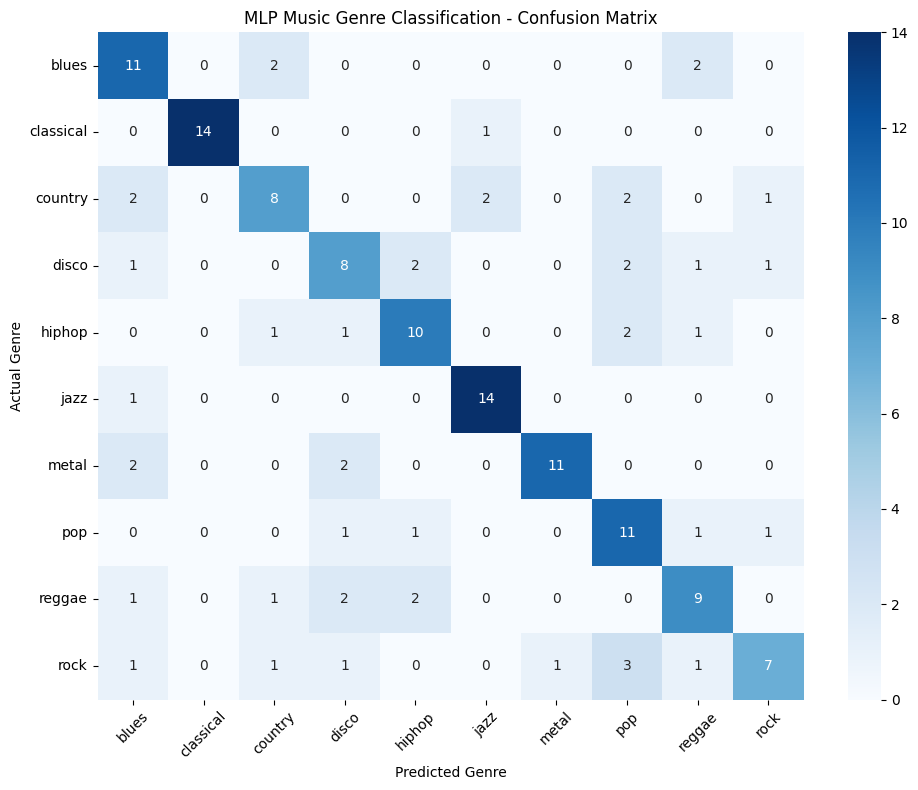

In [14]:

# STEP 15: Create a confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compare the actual genre labels with the predicted genre labels.
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

# Create a figure large enough to display all 10 genres.
plt.figure(figsize=(10, 8))

# Display the confusion matrix as a color-coded heatmap.
sns.heatmap(
    cm,
    annot=True,          # Show the number inside each cell.
    fmt="d",             # Display counts as integers.
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

# Label the axes and add a title.
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.title("MLP Music Genre Classification - Confusion Matrix")

# Rotate genre names to make them easier to read.
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


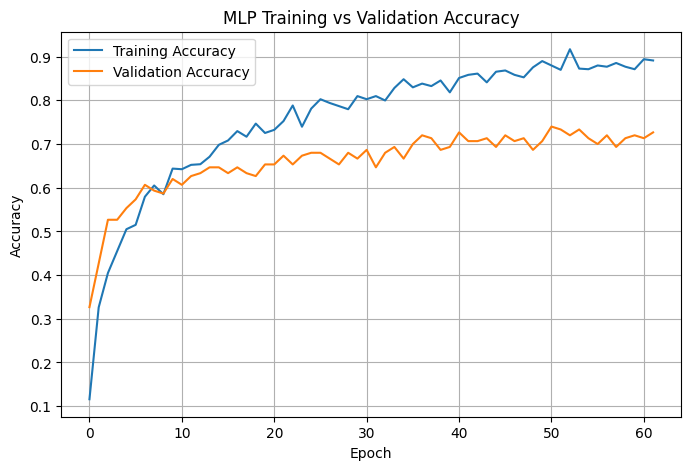

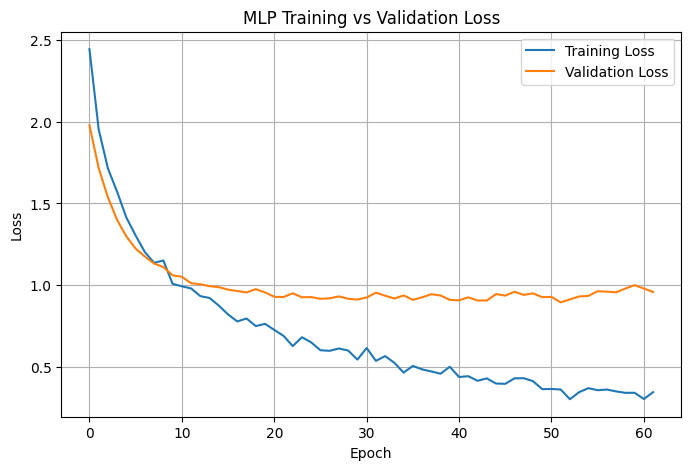

In [15]:

# STEP 16: Plot training and validation accuracy and loss

import matplotlib.pyplot as plt

# Get the values recorded during model training.
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

# Create a graph showing accuracy across epochs.
plt.figure(figsize=(8, 5))
plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Create a graph showing loss across epochs.
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [16]:
# STEP 17: Save the trained MLP model and preprocessing objects

import joblib

# Save the trained neural network
mlp_model.save("mlp_music_genre_model.keras")

# Save the scaler used to standardize the 56 audio features
joblib.dump(scaler, "mlp_feature_scaler.pkl")

# Save the encoder used to convert genre names into numbers
joblib.dump(label_encoder, "mlp_label_encoder.pkl")

print("Model and preprocessing objects saved successfully!")

Model and preprocessing objects saved successfully!
